In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# energía del láser (meV)
E = np.array([1339.4000, 1339.4375, 1339.4750, 1339.5125, 1339.5500,
              1339.5875, 1339.6250, 1339.6625, 1339.7000, 1339.7375,
              1339.7750, 1339.8125, 1339.8500, 1339.8875, 1339.9250,
              1339.9625, 1340.0000, 1340.0375, 1340.0750, 1340.1125,
              1340.1500, 1340.1875, 1340.2250, 1340.2625, 1340.3000])

# señal transmitida (kcuentas/s)
T = np.array([0.495, 0.580, 0.655, 0.745, 0.902, 1.047, 1.328,
              1.704, 1.873, 2.208, 2.695, 2.950, 3.016, 2.763,
              2.626, 2.358, 1.791, 1.560, 1.198, 1.031, 0.838,
              0.771, 0.622, 0.579, 0.499])

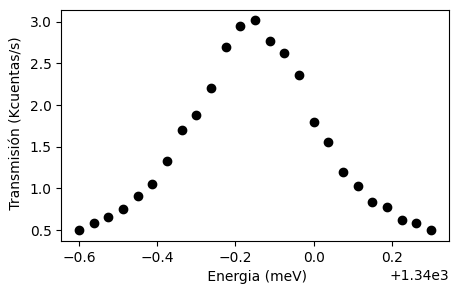

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(E, T, "ok")
plt.xlabel(" Energia (meV)")
plt.ylabel(" Transmisión (Kcuentas/s)")
plt.show()

In [ ]:
E[np.argmax(T)]

np.float64(1339.85)

In [ ]:
def f(x, th):
    A, γ, x0 = th
    return A*γ**2/((x-x0)**2 + γ**2 )

def Jacobian(x, th):
    A, γ, x0 = th
    u = x - x0
    D = u**2 + γ**2
    return np.column_stack(
        [
            γ**2/D,
            2*A*γ*u**2/D**2,
            2*A*γ**2*u/D**2
        ]
    )


def nonlinear_fit( f, th0, x, y, tol = 1e-8, maxiters = 10000 ):
    th = th0.copy()
    iters = [ th0 ]

    for k in range(maxiters):
        r = y - f(x, th)
        J = Jacobian(x,th)
        thn = np.linalg.solve( J.T @ J, J.T @ r )
        th = th + thn
        iters.append(th)

        if np.linalg.norm( thn ) < tol:
            break

    return th, iters

In [ ]:
th0 = np.array([T.max(),0.5, E[np.argmax(T)] ])
th, hist = nonlinear_fit(f, th0, E, T)

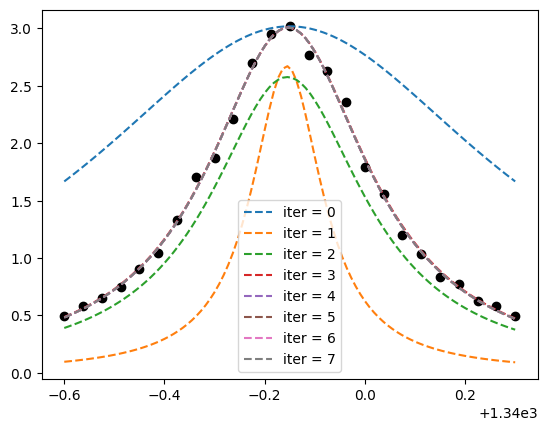

In [ ]:

x = np.linspace(E.min(), E.max(), 100 )
plt.plot(E,T, "ok")
for i,thi in enumerate(hist):
    A, γ, x0 = thi
    plt.plot( x, A*γ**2/((x-x0)**2 + γ**2), "--", label = f"iter = {i}" )
plt.legend()
plt.show()

In [ ]:
# semilla aleatoria
np.random.seed(1234)
σ = np.random.randn(T.shape[0])/5
W = np.diag(1/σ**2)

In [ ]:
def w_nonlinear_fit( f, th0, x, y, tol = 1e-8, maxiters = 10000 ):
    th = th0.copy()
    iters = [ th0 ]

    for k in range(maxiters):
        r = y - f(x, th)
        J = Jacobian(x,th)
        thn = np.linalg.solve( J.T @ W @ J, J.T @ W @ r )
        th = th + thn
        iters.append(th)

        if np.linalg.norm( thn ) < tol:
            break

    return th, iters

In [ ]:
#m = T > T.max()/2
#γ0 = (E[m].max() - E[m].min())/2
γ0 = (E[T.shape[0]//2] - E[0])/2

th0 = np.array([T.max(), γ0, E[np.argmax(T)] ])
th, hist = w_nonlinear_fit(f, th0, E, T)

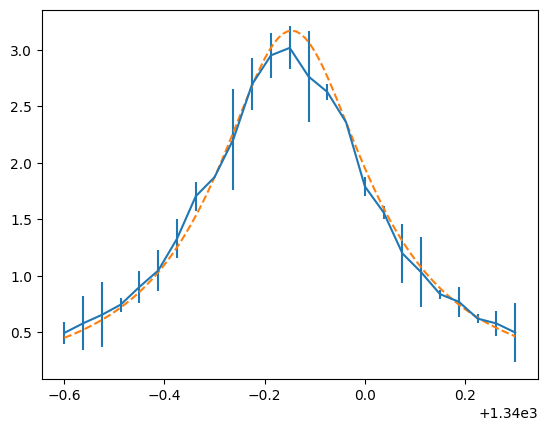

In [ ]:
A, γ, x0 = th
plt.errorbar( E, T, yerr=np.abs(σ) )
plt.plot( x, A*γ**2/((x-x0)**2 + γ**2), "--", )
plt.show()